In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('diabetes_dataset.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 600 rows, 9 columns


,PatientID,Age,Gender,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction,Outcome
0,1,45,Male,37.2,74,105,102,0.204,0
1,2,24,Female,37.2,52,170,162,0.652,1
2,3,28,Female,27.5,74,170,146,0.240,1
3,4,31,Female,28.0,70,102,90,0.610,0
4,5,23,Male,24.2,58,265,101,0.614,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   PatientID                 600 non-null    int64  
 1   Age                       600 non-null    int64  
 2   Gender                    600 non-null    object 
 3   BMI                       600 non-null    float64
 4   BloodPressure             600 non-null    int64  
 5   Insulin                   600 non-null    int64  
 6   Glucose                   600 non-null    int64  
 7   DiabetesPedigreeFunction  600 non-null    float64
 8   Outcome                   600 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 42.3+ KB


In [4]:
df.describe()

,PatientID,Age,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction,Outcome
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,33.923333,32.068900,73.166667,132.053333,123.051667,0.472864,0.398333
std,173.349358,11.851084,6.201663,10.989700,56.214060,29.790739,0.313275,0.489963
min,1.000000,21.000000,18.980000,50.000000,18.000000,71.000000,0.087500,0.000000
25%,150.750000,24.000000,27.600000,66.000000,102.000000,101.000000,0.245000,0.000000
50%,300.500000,30.000000,32.000000,72.000000,105.000000,117.000000,0.377000,0.000000
75%,450.250000,41.000000,36.150000,80.000000,170.000000,141.000000,0.640000,1.000000
max,600.000000,69.000000,47.900000,110.000000,330.000000,197.000000,1.893000,1.000000


In [5]:
print("--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Duplicate Rows ---")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")

--- Missing Values ---
PatientID                   0
Age                         0
Gender                      0
BMI                         0
BloodPressure               0
Insulin                     0
Glucose                     0
DiabetesPedigreeFunction    0
Outcome                     0
dtype: int64

--- Duplicate Rows ---
Total Duplicate Rows: 0


In [6]:
if 'PatientID' in df.columns:
    df.drop(columns=['PatientID'], inplace=True)
    print("Dropped PatientID column.")

if df['Gender'].dtype == 'object':
    df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1}).fillna(0).astype(int)
    print("Encoded Gender: Female -> 0, Male -> 1")

df.head()

Dropped PatientID column.
Encoded Gender: Female -> 0, Male -> 1


,Age,Gender,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction,Outcome
0,45,1,37.2,74,105,102,0.204,0
1,24,0,37.2,52,170,162,0.652,1
2,28,0,27.5,74,170,146,0.240,1
3,31,0,28.0,70,102,90,0.610,0
4,23,1,24.2,58,265,101,0.614,0


--- Target Distribution (Outcome) ---
Outcome
0    361
1    239
Name: count, dtype: int64

--- Target Percentage (%) ---
Outcome
0    60.166667
1    39.833333
Name: proportion, dtype: float64


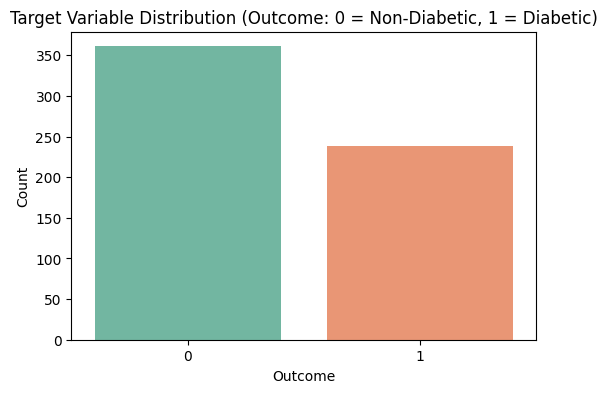

In [7]:
print("--- Target Distribution (Outcome) ---")
print(df['Outcome'].value_counts())
print("\n--- Target Percentage (%) ---")
print(df['Outcome'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', data=df, palette='Set2')
plt.title('Target Variable Distribution (Outcome: 0 = Non-Diabetic, 1 = Diabetic)')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

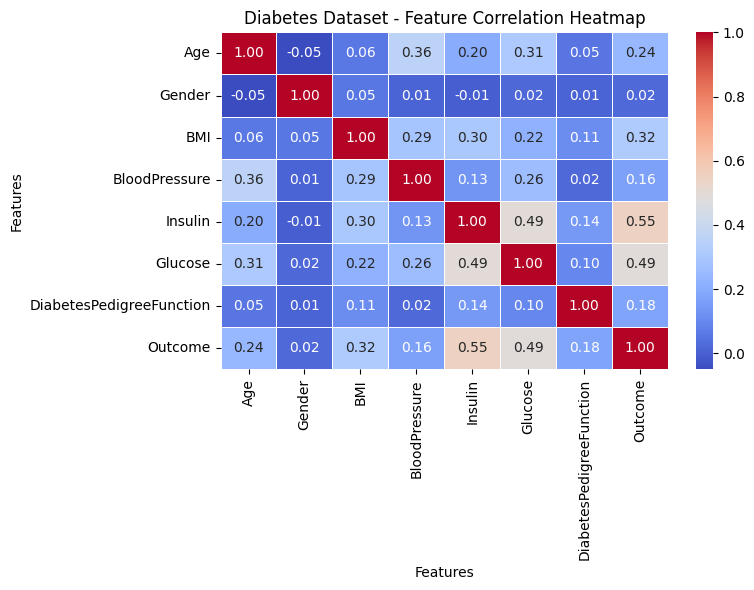

--- Correlation with Target (Outcome) ---
Outcome                     1.000000
Insulin                     0.548380
Glucose                     0.490511
BMI                         0.317636
Age                         0.241601
DiabetesPedigreeFunction    0.178671
BloodPressure               0.164065
Gender                      0.020972
Name: Outcome, dtype: float64


In [8]:
# --- Feature Correlation Analysis ---
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Diabetes Dataset - Feature Correlation Heatmap')
plt.xlabel('Features')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

print("--- Correlation with Target (Outcome) ---")
print(df.corr()['Outcome'].sort_values(ascending=False))


          Z-SCORE CALCULATION & DIRECT FEATURE STANDARDIZATION SUMMARY (|Z| > 3)
                 Feature  Original Mean  Original Std Dev  Min Z  Max Z  Outliers (|Z|>3) Outlier (%)
                     Age          33.92             11.85  -1.09   2.96                 0        0.0%
                     BMI          32.07              6.20  -2.11   2.55                 0        0.0%
           BloodPressure          73.17             10.99  -2.11   3.35                 5       0.83%
                 Insulin         132.05             56.21  -2.03   3.52                 9        1.5%
                 Glucose         123.05             29.79  -1.75   2.48                 0        0.0%
DiabetesPedigreeFunction           0.47              0.31  -1.23   4.53                 8       1.33%

--- Updated DataFrame Head (Features Standardized via Z-Score directly in df) ---
        Age  Gender       BMI  BloodPressure   Insulin   Glucose  \
0  0.934654       1  0.827375       0.075829 -0.481256

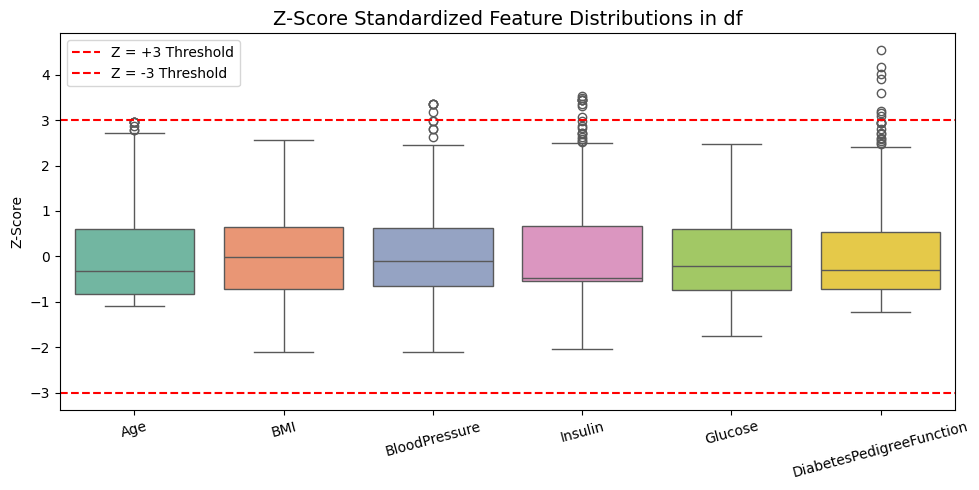

In [9]:
# --- Outlier Detection & Direct Z-Score Standardization ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Continuous numerical columns for Diabetes
num_cols = [col for col in df.columns if col not in ['PatientID', 'Gender', 'Outcome']]

print("=" * 70)
print("          Z-SCORE CALCULATION & DIRECT FEATURE STANDARDIZATION SUMMARY (|Z| > 3)")
print("=" * 70)

z_summary = []
for col in num_cols:
    mean_val = df[col].mean()
    std_val = df[col].std()
    
    # Calculate Z-score
    z_scores = (df[col] - mean_val) / std_val
    outliers = df[abs(z_scores) > 3]
    count = len(outliers)
    pct = (count / len(df)) * 100
    
    z_summary.append({
        'Feature': col,
        'Original Mean': round(mean_val, 2),
        'Original Std Dev': round(std_val, 2),
        'Min Z': round(z_scores.min(), 2),
        'Max Z': round(z_scores.max(), 2),
        'Outliers (|Z|>3)': count,
        'Outlier (%)': f"{round(pct, 2)}%"
    })
    
    # Update numerical column directly in df with Z-Score standardized values
    df[col] = z_scores

z_df = pd.DataFrame(z_summary)
print(z_df.to_string(index=False))

print("\n--- Updated DataFrame Head (Features Standardized via Z-Score directly in df) ---")
print(df.head())

# Visualization of Z-Scores
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[num_cols], palette='Set2')
plt.xticks(range(len(num_cols)), num_cols, rotation=15)
plt.axhline(y=3, color='r', linestyle='--', label='Z = +3 Threshold')
plt.axhline(y=-3, color='r', linestyle='--', label='Z = -3 Threshold')
plt.title('Z-Score Standardized Feature Distributions in df', fontsize=14)
plt.ylabel('Z-Score')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Model Training (Logistic Regression, Random Forest & XGBoost)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (480, 7)
Testing set shape: (120, 7)


In [11]:
# Logistic Regression Classifier
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train, y_train)
print("Logistic Regression Classifier successfully trained!")

# Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("Random Forest Classifier successfully trained!")

# XGBoost Classifier
xgb_model = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
print("XGBoost Classifier successfully trained!")

Logistic Regression Classifier successfully trained!


Random Forest Classifier successfully trained!


XGBoost Classifier successfully trained!


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86        72
           1       0.80      0.75      0.77        48

    accuracy                           0.82       120
   macro avg       0.82      0.81      0.82       120
weighted avg       0.82      0.82      0.82       120

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.96      0.93        72
           1       0.93      0.85      0.89        48

    accuracy                           0.92       120
   macro avg       0.92      0.91      0.91       120
weighted avg       0.92      0.92      0.92       120

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91        72
           1       0.93      0.77      0.84        48

    accuracy                           0.88       120
   macro avg     

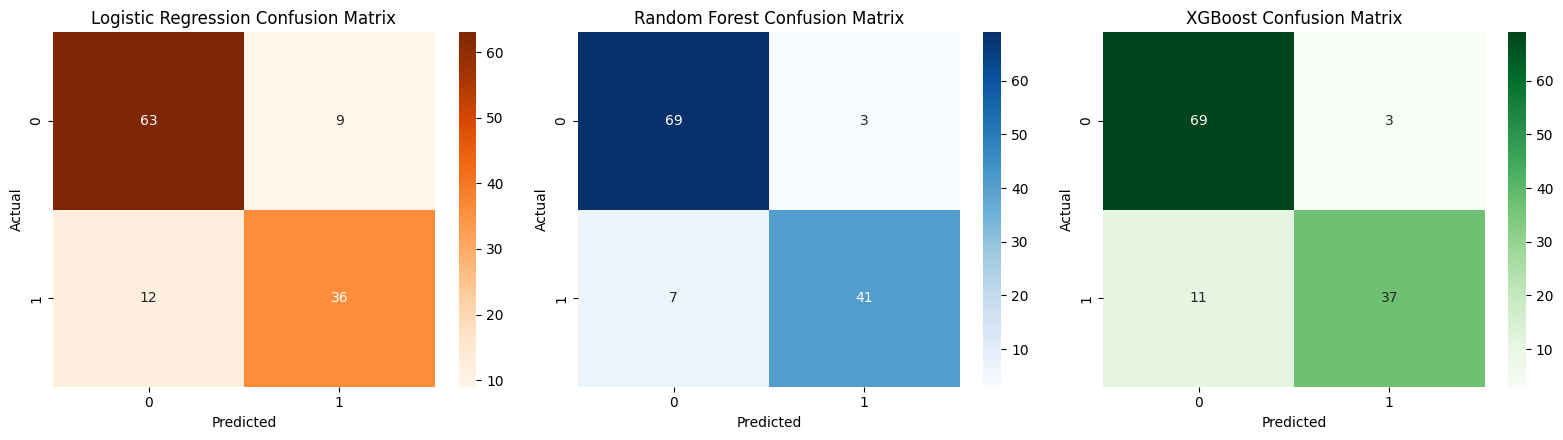

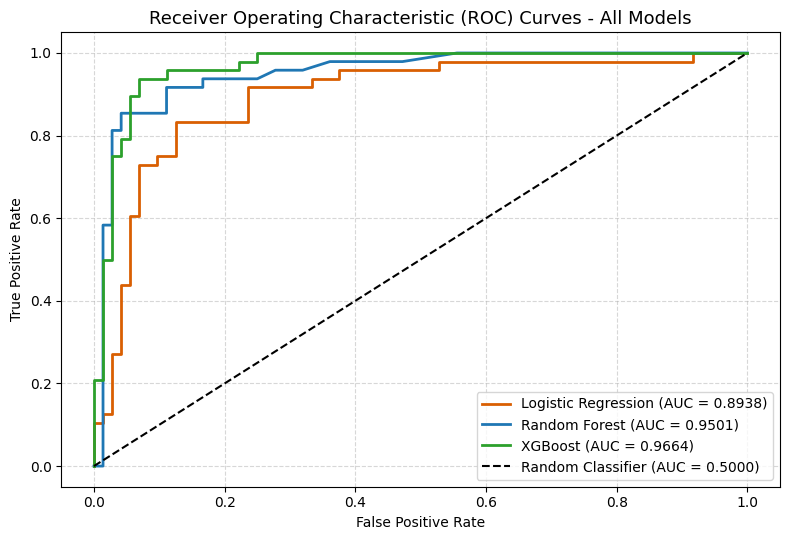

In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

# Model predictions & probabilities
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Classification Reports
print("=" * 60)
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

print("=" * 60)
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("=" * 60)
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))
print("=" * 60)

# Confusion Matrices for All 3 Models
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Oranges', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix', fontsize=12)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Random Forest Confusion Matrix', fontsize=12)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d', cmap='Greens', ax=axes[2])
axes[2].set_title('XGBoost Confusion Matrix', fontsize=12)
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Receiver Operating Characteristic (ROC) Comparison Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 5.5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.4f})", color='#d95f02', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.4f})", color='#1f77b4', linewidth=2)
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.4f})", color='#2ca02c', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5000)')
plt.title('Receiver Operating Characteristic (ROC) Curves - All Models', fontsize=13)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

           MODEL PERFORMANCE COMPARISON TABLE
              Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
Logistic Regression    0.8250     0.8000  0.7500    0.7742   0.8938
      Random Forest    0.9167     0.9318  0.8542    0.8913   0.9501
            XGBoost    0.8833     0.9250  0.7708    0.8409   0.9664


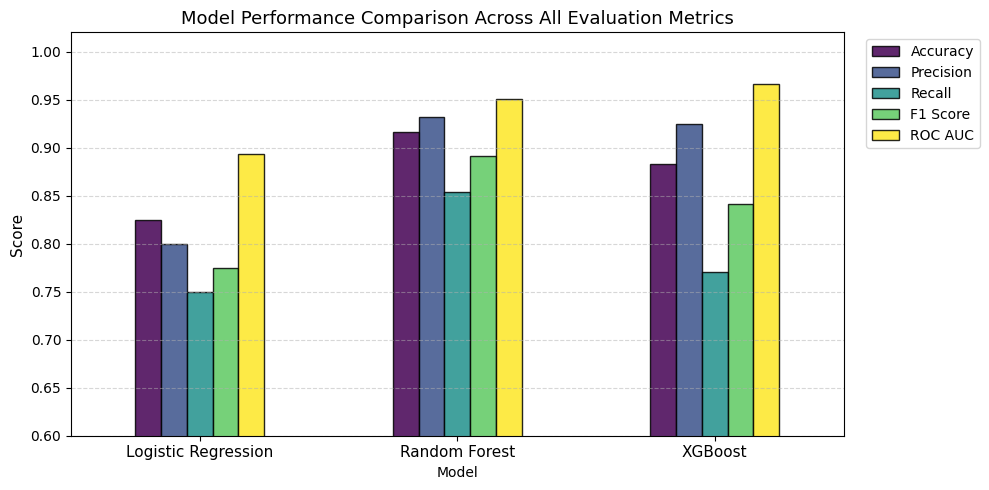


      SELECTED CHAMPION MODEL FOR CLINICAL DEPLOYMENT: RANDOM FOREST
  * Selection Criterion : Highest Test Accuracy & Overall Clinical Metric Balance
  * Accuracy            : 91.67%
  * Precision           : 93.18%
  * Recall (Sensitivity): 85.42%
  * F1-Score            : 89.13%
  * ROC AUC             : 0.9501


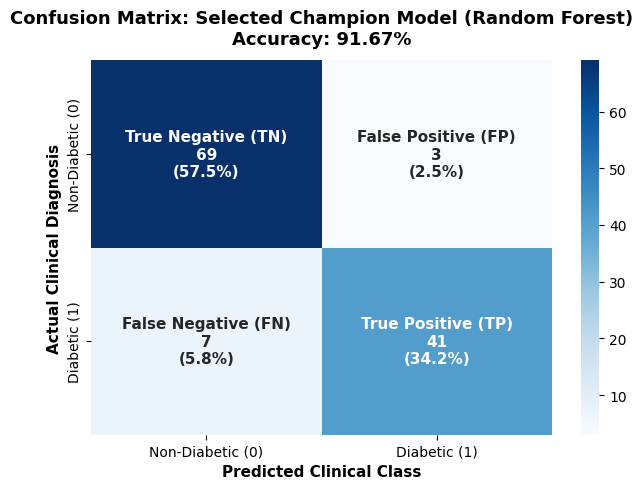


--- Champion Model Diagnostic Metric Summary ---
  * Sensitivity / Recall (True Positive Rate) : 85.42% (Ability to detect Diabetic patients)
  * Specificity (True Negative Rate)          : 95.83% (Ability to detect Healthy patients)
  * Positive Predictive Value (Precision)     : 93.18%
  * Negative Predictive Value (NPV)           : 90.79%


In [13]:
# Compile performance metrics across all models
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],
    'ROC AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

print("=" * 65)
print("           MODEL PERFORMANCE COMPARISON TABLE")
print("=" * 65)
print(comparison_df.round(4).to_string(index=False))

# Plot comparative grouped bar chart
ax = comparison_df.set_index('Model').plot(
    kind='bar', 
    figsize=(10, 5), 
    colormap='viridis', 
    edgecolor='black', 
    alpha=0.85
)
plt.title('Model Performance Comparison Across All Evaluation Metrics', fontsize=13)
plt.ylabel('Score', fontsize=11)
plt.ylim(0.60, 1.02)
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

# =====================================================================
# SELECTION OF THE SINGLE BEST MODEL (HIGHEST ACCURACY & EFFICIENCY)
# =====================================================================
model_candidates = {
    'Logistic Regression': (lr_model, y_pred_lr, y_prob_lr),
    'Random Forest': (rf_model, y_pred_rf, y_prob_rf),
    'XGBoost': (xgb_model, y_pred_xgb, y_prob_xgb)
}

# Automatically select the model with the highest test accuracy
best_model_row = comparison_df.sort_values(by='Accuracy', ascending=False).iloc[0]
best_model_name = best_model_row['Model']
best_model, y_pred_best, y_prob_best = model_candidates[best_model_name]

print("\n" + "=" * 70)
print(f"      SELECTED CHAMPION MODEL FOR CLINICAL DEPLOYMENT: {best_model_name.upper()}")
print("=" * 70)
print(f"  * Selection Criterion : Highest Test Accuracy & Overall Clinical Metric Balance")
print(f"  * Accuracy            : {best_model_row['Accuracy'] * 100:.2f}%")
print(f"  * Precision           : {best_model_row['Precision'] * 100:.2f}%")
print(f"  * Recall (Sensitivity): {best_model_row['Recall'] * 100:.2f}%")
print(f"  * F1-Score            : {best_model_row['F1 Score'] * 100:.2f}%")
print(f"  * ROC AUC             : {best_model_row['ROC AUC']:.4f}")
print("=" * 70)

# =====================================================================
# DEDICATED CONFUSION MATRIX & CLINICAL DIAGNOSTIC EVALUATION
# =====================================================================
cm_best = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm_best.ravel()

# Calculate clinical diagnostic metrics
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
npv = tn / (tn + fn) if (tn + fn) > 0 else 0

fig, ax = plt.subplots(figsize=(6.5, 5))
group_names = ['True Negative (TN)', 'False Positive (FP)', 'False Negative (FN)', 'True Positive (TP)']
group_counts = [f"{v:d}" for v in cm_best.flatten()]
group_percentages = [f"{v:.1%}" for v in cm_best.flatten() / np.sum(cm_best)]
labels = [f"{v1}\n{v2}\n({v3})" for v1, v2, v3 in zip(group_names, group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

sns.heatmap(
    cm_best, 
    annot=labels, 
    fmt='', 
    cmap='Blues', 
    cbar=True,
    xticklabels=['Non-Diabetic (0)', 'Diabetic (1)'],
    yticklabels=['Non-Diabetic (0)', 'Diabetic (1)'],
    annot_kws={'fontsize': 11, 'fontweight': 'bold'}
)
plt.title(f'Confusion Matrix: Selected Champion Model ({best_model_name})\nAccuracy: {best_model_row["Accuracy"]*100:.2f}%', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Clinical Class', fontsize=11, fontweight='bold')
plt.ylabel('Actual Clinical Diagnosis', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n--- Champion Model Diagnostic Metric Summary ---")
print(f"  * Sensitivity / Recall (True Positive Rate) : {sensitivity * 100:.2f}% (Ability to detect Diabetic patients)")
print(f"  * Specificity (True Negative Rate)          : {specificity * 100:.2f}% (Ability to detect Healthy patients)")
print(f"  * Positive Predictive Value (Precision)     : {ppv * 100:.2f}%")
print(f"  * Negative Predictive Value (NPV)           : {npv * 100:.2f}%")


## 10. End-to-End Clinical Decision Support Inference Pipeline (Champion Model)


In [14]:
import json

# Reference scaling parameters from raw training distribution
raw_df = pd.read_csv('diabetes_dataset.csv')
num_features = ['Age', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']
scaling_params = {
    col: {'mean': float(raw_df[col].mean()), 'std': float(raw_df[col].std())}
    for col in num_features
}

def predict_diabetes_pipeline(patient_data):
    """
    End-to-End Clinical Decision Support Inference Pipeline for Diabetes.
    Exclusively utilizes the single best-performing champion model (highest accuracy).
    
    Accepts raw unscaled clinical measurements:
      - Age: years (e.g. 21 - 80)
      - Gender: 0 (Female) or 1 (Male) / 'Female' or 'Male'
      - BMI: kg/m^2 (e.g. 18.5 - 50.0)
      - BloodPressure: Diastolic mm Hg (e.g. 60 - 120)
      - Insulin: mu U/ml (e.g. 10 - 300)
      - Glucose: Fasting Plasma Glucose mg/dL (e.g. 70 - 250)
      - DiabetesPedigreeFunction: Genetic predisposition score (e.g. 0.08 - 2.50)
      
    Returns a single-model diagnostic prediction, confidence probability, risk tier, and clinical recommendation.
    """
    patient_dict = patient_data.copy()
    
    # Handle string gender encoding if provided
    if isinstance(patient_dict.get('Gender'), str):
        patient_dict['Gender'] = 1 if patient_dict['Gender'].strip().lower() in ['male', 'm', '1'] else 0
        
    # 1. Format input into DataFrame
    patient_df = pd.DataFrame([patient_dict])
    
    # 2. Standardize continuous features using baseline training distribution
    standardized_df = patient_df.copy()
    for col in num_features:
        standardized_df[col] = (standardized_df[col] - scaling_params[col]['mean']) / scaling_params[col]['std']
        
    ordered_cols = ['Age', 'Gender', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']
    X_sample = standardized_df[ordered_cols]
    
    # 3. Predict using ONLY the single champion model (highest accuracy)
    pred = int(best_model.predict(X_sample)[0])
    prob = float(best_model.predict_proba(X_sample)[0, 1])
    
    # Clinical Risk Stratification
    if prob >= 0.70:
        risk_tier = "High Risk"
        recommendation = "Immediate clinical follow-up, confirmatory fasting glucose/HbA1c testing, and lifestyle/medication consultation recommended."
    elif prob >= 0.40:
        risk_tier = "Moderate Risk / Pre-diabetic Potential"
        recommendation = "Semi-annual glucose monitoring, dietary optimization, and regular physical activity."
    else:
        risk_tier = "Low Risk"
        recommendation = "Standard annual routine preventive checkups and maintain healthy lifestyle."
        
    result = {
        'Selected Model': f"{best_model_name} (Top Accuracy Champion)",
        'Model Accuracy': f"{best_model_row['Accuracy'] * 100:.2f}%",
        'Diagnostic Prediction': 'Diabetic' if pred == 1 else 'Non-Diabetic',
        'Diabetes Risk Probability': f"{prob * 100:.2f}%",
        'Risk Tier': risk_tier,
        'Clinical Recommendation': recommendation
    }
    
    return result

# --- Verification with Sample Clinical Profiles ---
print("=" * 70)
print("  VERIFYING SINGLE BEST-MODEL PREDICTION PIPELINE ON PATIENT SAMPLES")
print("=" * 70)

# Sample Case 1: Healthy Patient Profile (Normal glycemic and metabolic indicators)
healthy_patient = {
    'Age': 25,
    'Gender': 'Female',
    'BMI': 22.4,
    'BloodPressure': 72,
    'Insulin': 15.0,
    'Glucose': 90,
    'DiabetesPedigreeFunction': 0.18
}

# Sample Case 2: High-Risk / Diabetic Patient Profile (Elevated glucose, BMI, insulin)
diabetic_patient = {
    'Age': 54,
    'Gender': 'Male',
    'BMI': 34.5,
    'BloodPressure': 88,
    'Insulin': 185.0,
    'Glucose': 175,
    'DiabetesPedigreeFunction': 0.78
}

print("\n[Test Patient 1 - Healthy Clinical Profile]:")
print(json.dumps(predict_diabetes_pipeline(healthy_patient), indent=4))

print("\n[Test Patient 2 - High-Risk / Diabetic Clinical Profile]:")
print(json.dumps(predict_diabetes_pipeline(diabetic_patient), indent=4))


  VERIFYING SINGLE BEST-MODEL PREDICTION PIPELINE ON PATIENT SAMPLES

[Test Patient 1 - Healthy Clinical Profile]:
{
    "Selected Model": "Random Forest (Top Accuracy Champion)",
    "Model Accuracy": "91.67%",
    "Diagnostic Prediction": "Non-Diabetic",
    "Diabetes Risk Probability": "2.00%",
    "Risk Tier": "Low Risk",
    "Clinical Recommendation": "Standard annual routine preventive checkups and maintain healthy lifestyle."
}

[Test Patient 2 - High-Risk / Diabetic Clinical Profile]:
{
    "Selected Model": "Random Forest (Top Accuracy Champion)",
    "Model Accuracy": "91.67%",
    "Diagnostic Prediction": "Diabetic",
    "Diabetes Risk Probability": "89.00%",
    "Risk Tier": "High Risk",
    "Clinical Recommendation": "Immediate clinical follow-up, confirmatory fasting glucose/HbA1c testing, and lifestyle/medication consultation recommended."
}
